# Evaluation, calibration and explainability 

This notebook reads outputs from `scripts/run_evaluation_explainability.py`; it does not fit or select models. All reported results are validation-only. The held-out test partition remains locked.

In [8]:
from pathlib import Path
import sys
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.metrics import ConfusionMatrixDisplay, PrecisionRecallDisplay, RocCurveDisplay

ROOT = Path.cwd().resolve()
if not (ROOT / 'src').is_dir():
    ROOT = ROOT.parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
TABLES = ROOT / 'results' / 'tables' / '04_evaluation'
FIGURES = ROOT / 'results' / 'figures' / '04_evaluation'
FIGURES.mkdir(parents=True, exist_ok=True)
summary = pd.read_csv(TABLES / 'evaluation_summary.csv')
selected = summary[summary['selected_for_model']].copy()
selected['candidate_name'] = np.where(
    selected['calibration_method'].eq('uncalibrated'),
    selected['model_name'],
    selected['model_name'] + '__' + selected['calibration_method'],
)
display(summary.round(4))
print('Selected by validation Brier score, then log loss:')
display(selected[['model_name', 'calibration_method', 'brier_score', 'log_loss',
                  'expected_calibration_error', 'roc_auc',
                  'pr_auc_average_precision']].round(4))

,model_name,calibration_method,selected_for_model,roc_auc,pr_auc_average_precision,brier_score,log_loss,expected_calibration_error,maximum_calibration_error,threshold,precision,recall,f1,tn,fp,fn,tp
0,logistic_tuned,uncalibrated,False,0.8021,0.3136,0.1794,0.5821,0.3455,0.4610,0.5,0.1823,0.6682,0.2865,16489,4507,499,1005
1,logistic_tuned,sigmoid,False,0.8017,0.3123,0.0619,0.2421,0.0526,0.2343,0.5,0.5106,0.0160,0.0309,20973,23,1480,24
2,logistic_tuned,isotonic,True,0.8020,0.3124,0.0529,0.1996,0.0042,0.0127,0.5,0.5627,0.1403,0.2246,20832,164,1293,211
3,random_forest_tuned,uncalibrated,False,0.8694,0.4013,0.0487,0.1762,0.0058,0.0300,0.5,0.5887,0.1523,0.2419,20836,160,1275,229
4,random_forest_tuned,sigmoid,False,0.8691,0.4014,0.0500,0.1858,0.0205,0.0540,0.5,0.5838,0.2154,0.3147,20765,231,1180,324
5,random_forest_tuned,isotonic,True,0.8690,0.3994,0.0487,0.1760,0.0029,0.0128,0.5,0.6059,0.1636,0.2576,20836,160,1258,246
6,xgboost_standard_tuned,uncalibrated,False,0.8701,0.4042,0.0485,0.1756,0.0042,0.0170,0.5,0.5905,0.1822,0.2785,20806,190,1230,274
7,xgboost_standard_tuned,sigmoid,False,0.8703,0.4050,0.0501,0.1865,0.0216,0.0514,0.5,0.5842,0.2261,0.3260,20754,242,1164,340
8,xgboost_standard_tuned,isotonic,True,0.8703,0.4030,0.0485,0.1753,0.0029,0.0117,0.5,0.5862,0.1809,0.2764,20804,192,1232,272


Selected by validation Brier score, then log loss:


,model_name,calibration_method,brier_score,log_loss,expected_calibration_error,roc_auc,pr_auc_average_precision
2,logistic_tuned,isotonic,0.0529,0.1996,0.0042,0.8020,0.3124
5,random_forest_tuned,isotonic,0.0487,0.1760,0.0029,0.8690,0.3994
8,xgboost_standard_tuned,isotonic,0.0485,0.1753,0.0029,0.8703,0.4030


## Discrimination
ROC-AUC and average precision assess ranking. Curves below use exactly the same validation observations, verified through the shared prediction schema.

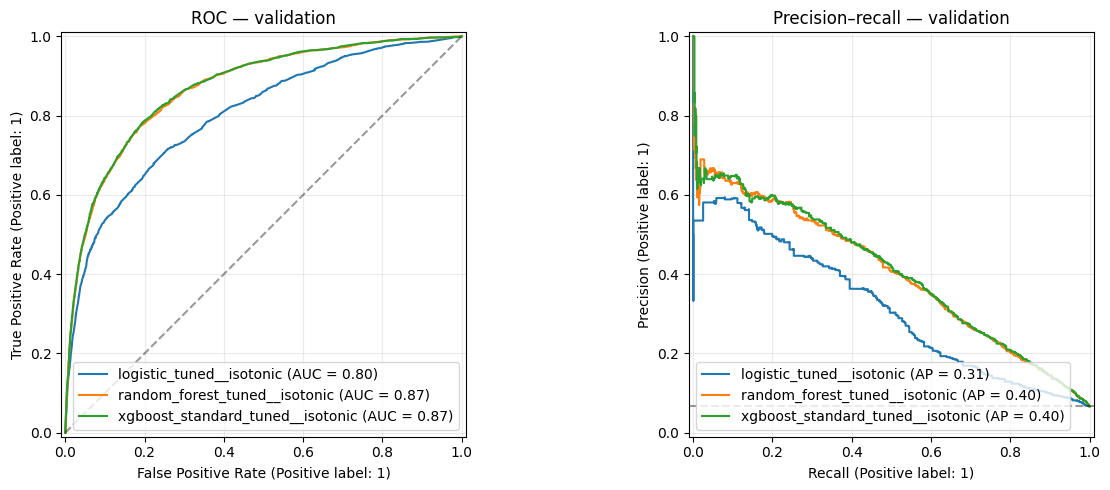

In [9]:
predictions = {}
for row in selected.itertuples():
    frame = pd.read_csv(TABLES / f'{row.candidate_name}_validation_predictions.csv')
    assert frame['split'].eq('validation').all()
    predictions[row.candidate_name] = frame.sort_values('sample_id')
reference = next(iter(predictions.values()))[['sample_id', 'y_true']]
for name, frame in predictions.items():
    pd.testing.assert_frame_equal(frame[['sample_id', 'y_true']].reset_index(drop=True),
                                  reference.reset_index(drop=True))
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for name, frame in predictions.items():
    RocCurveDisplay.from_predictions(frame['y_true'], frame['y_pred_proba'], name=name, ax=axes[0])
    PrecisionRecallDisplay.from_predictions(frame['y_true'], frame['y_pred_proba'], name=name, ax=axes[1])
axes[0].plot([0, 1], [0, 1], 'k--', alpha=.4)
axes[1].axhline(reference['y_true'].mean(), color='k', linestyle='--', alpha=.4)
axes[0].set_title('ROC — validation')
axes[1].set_title('Precision–recall — validation')
for ax in axes: ax.grid(alpha=.25)
plt.tight_layout(); plt.savefig(FIGURES / 'roc_pr_validation.png', dpi=160, bbox_inches='tight'); plt.show()

## Decision metrics at the fixed reporting threshold
These confusion matrices use threshold 0.5 for consistent reporting, not as a cost-optimal decision rule. Threshold selection belongs to Member 5.

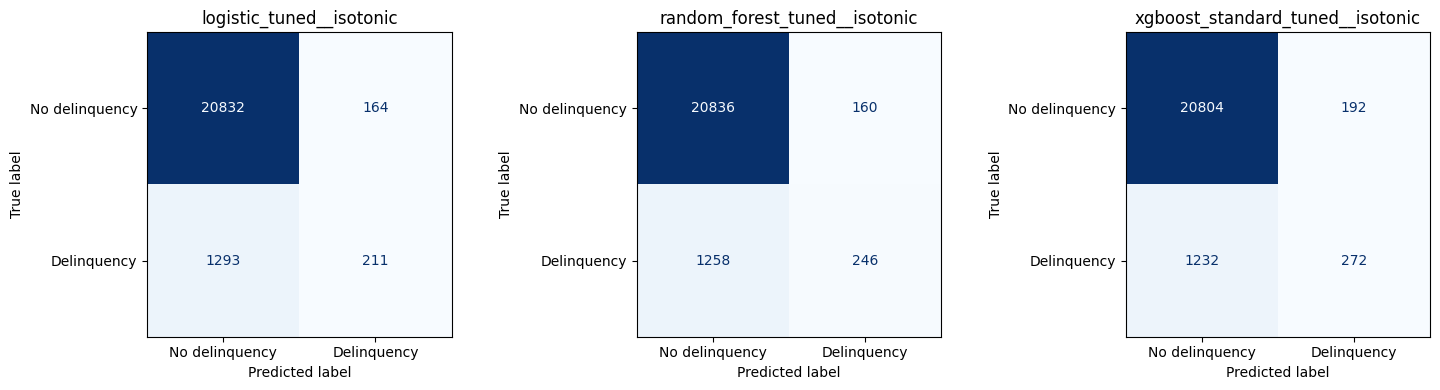

In [10]:
fig, axes = plt.subplots(1, len(predictions), figsize=(5 * len(predictions), 4), squeeze=False)
for ax, (name, frame) in zip(axes.flat, predictions.items()):
    ConfusionMatrixDisplay.from_predictions(
        frame['y_true'], (frame['y_pred_proba'] >= .5).astype(int),
        labels=[0, 1], display_labels=['No delinquency', 'Delinquency'],
        cmap='Blues', colorbar=False, ax=ax,
    )
    ax.set_title(name)
plt.tight_layout(); plt.savefig(FIGURES / 'confusion_matrices_validation.png', dpi=160, bbox_inches='tight'); plt.show()

## Probability calibration
Sigmoid and isotonic calibration are fit only through stratified training folds. The selected candidate minimizes validation Brier score, with log loss as a deterministic tie-break. ECE/MCE are descriptive and depend on binning.

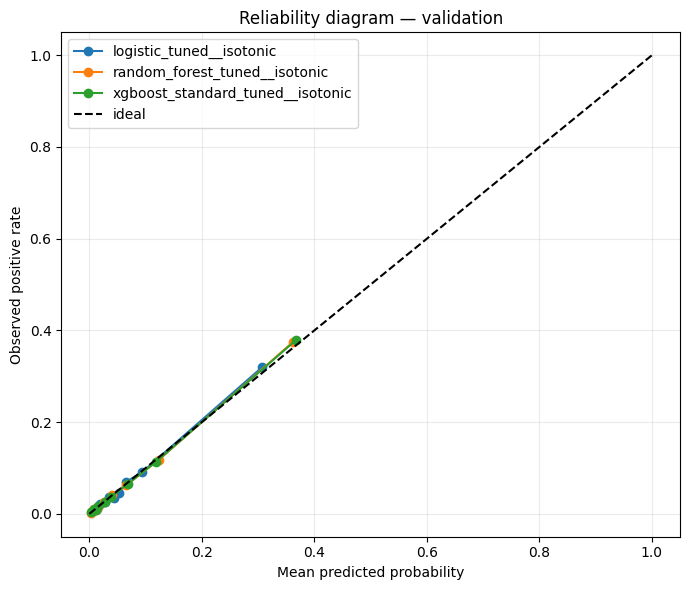

In [11]:
fig, ax = plt.subplots(figsize=(7, 6))
for row in selected.itertuples():
    bins = pd.read_csv(TABLES / f'{row.candidate_name}_calibration_bins.csv')
    ax.plot(bins['mean_predicted_probability'], bins['observed_positive_rate'],
            marker='o', label=row.candidate_name)
ax.plot([0, 1], [0, 1], 'k--', label='ideal')
ax.set(xlabel='Mean predicted probability', ylabel='Observed positive rate',
       title='Reliability diagram — validation')
ax.grid(alpha=.25); ax.legend(); plt.tight_layout(); plt.savefig(FIGURES / 'reliability_validation.png', dpi=160, bbox_inches='tight'); plt.show()

## Uncertainty and duplicate sensitivity
Percentile intervals use 1,000 class-stratified bootstrap resamples. Pairwise deltas reuse the same resampled observations. The duplicate sensitivity table keeps the approved split unchanged and reports metrics after excluding validation rows that exactly match a training row.

In [12]:
intervals = pd.read_csv(TABLES / 'bootstrap_confidence_intervals.csv')
pairwise = pd.read_csv(TABLES / 'paired_bootstrap_differences.csv')
duplicate_sensitivity = pd.read_csv(TABLES / 'duplicate_sensitivity.csv')
display(intervals.round(4))
display(pairwise.round(4))
display(duplicate_sensitivity.round(4))

,base_model,candidate_name,metric,estimate,ci_lower,ci_upper,confidence_level,n_resamples
0,logistic_tuned,logistic_tuned__isotonic,roc_auc,0.8020,0.7889,0.8145,0.95,1000
1,logistic_tuned,logistic_tuned__isotonic,pr_auc_average_precision,0.3124,0.2906,0.3357,0.95,1000
2,logistic_tuned,logistic_tuned__isotonic,brier_score,0.0529,0.0519,0.0540,0.95,1000
3,logistic_tuned,logistic_tuned__isotonic,log_loss,0.1996,0.1951,0.2053,0.95,1000
4,random_forest_tuned,random_forest_tuned__isotonic,roc_auc,0.8690,0.8593,0.8787,0.95,1000
5,random_forest_tuned,random_forest_tuned__isotonic,pr_auc_average_precision,0.3994,0.3753,0.4251,0.95,1000
6,random_forest_tuned,random_forest_tuned__isotonic,brier_score,0.0487,0.0476,0.0498,0.95,1000
7,random_forest_tuned,random_forest_tuned__isotonic,log_loss,0.1760,0.1718,0.1803,0.95,1000
8,xgboost_standard_tuned,xgboost_standard_tuned__isotonic,roc_auc,0.8703,0.8605,0.8798,0.95,1000
9,xgboost_standard_tuned,xgboost_standard_tuned__isotonic,pr_auc_average_precision,0.4030,0.3790,0.4275,0.95,1000


,base_model_a,base_model_b,candidate_a,candidate_b,metric,delta_model_b_minus_model_a,ci_lower,ci_upper,metric_direction,bootstrap_probability_model_b_better,confidence_level,n_resamples
0,logistic_tuned,random_forest_tuned,logistic_tuned__isotonic,random_forest_tuned__isotonic,roc_auc,0.0670,0.0577,0.0765,higher_is_better,1.000,0.95,1000
1,logistic_tuned,random_forest_tuned,logistic_tuned__isotonic,random_forest_tuned__isotonic,pr_auc_average_precision,0.0869,0.0706,0.1038,higher_is_better,1.000,0.95,1000
2,logistic_tuned,random_forest_tuned,logistic_tuned__isotonic,random_forest_tuned__isotonic,brier_score,-0.0042,-0.0050,-0.0035,lower_is_better,1.000,0.95,1000
3,logistic_tuned,random_forest_tuned,logistic_tuned__isotonic,random_forest_tuned__isotonic,log_loss,-0.0237,-0.0279,-0.0201,lower_is_better,1.000,0.95,1000
4,logistic_tuned,xgboost_standard_tuned,logistic_tuned__isotonic,xgboost_standard_tuned__isotonic,roc_auc,0.0683,0.0594,0.0778,higher_is_better,1.000,0.95,1000
5,logistic_tuned,xgboost_standard_tuned,logistic_tuned__isotonic,xgboost_standard_tuned__isotonic,pr_auc_average_precision,0.0906,0.0749,0.1070,higher_is_better,1.000,0.95,1000
6,logistic_tuned,xgboost_standard_tuned,logistic_tuned__isotonic,xgboost_standard_tuned__isotonic,brier_score,-0.0044,-0.0051,-0.0037,lower_is_better,1.000,0.95,1000
7,logistic_tuned,xgboost_standard_tuned,logistic_tuned__isotonic,xgboost_standard_tuned__isotonic,log_loss,-0.0243,-0.0286,-0.0209,lower_is_better,1.000,0.95,1000
8,random_forest_tuned,xgboost_standard_tuned,random_forest_tuned__isotonic,xgboost_standard_tuned__isotonic,roc_auc,0.0013,-0.0000,0.0026,higher_is_better,0.973,0.95,1000
9,random_forest_tuned,xgboost_standard_tuned,random_forest_tuned__isotonic,xgboost_standard_tuned__isotonic,pr_auc_average_precision,0.0037,-0.0011,0.0087,higher_is_better,0.924,0.95,1000


,base_model,candidate_name,subset,n_observations,n_positive,roc_auc,pr_auc_average_precision,brier_score,log_loss
0,logistic_tuned,logistic_tuned__isotonic,all_validation,22500,1504,0.8020,0.3124,0.0529,0.1996
1,logistic_tuned,logistic_tuned__isotonic,excluding_exact_train_duplicates,22384,1501,0.8016,0.3146,0.0531,0.2001
2,random_forest_tuned,random_forest_tuned__isotonic,all_validation,22500,1504,0.8690,0.3994,0.0487,0.1760
3,random_forest_tuned,random_forest_tuned__isotonic,excluding_exact_train_duplicates,22384,1501,0.8688,0.3992,0.0489,0.1764
4,xgboost_standard_tuned,xgboost_standard_tuned__isotonic,all_validation,22500,1504,0.8703,0.4030,0.0485,0.1753
5,xgboost_standard_tuned,xgboost_standard_tuned__isotonic,excluding_exact_train_duplicates,22384,1501,0.8702,0.4030,0.0487,0.1758


## Global SHAP importance
Mean absolute SHAP magnitude describes how strongly the selected XGBoost ranking model uses each transformed feature. It does not establish causality.

,feature,mean_absolute_shap,mean_shap
0,RevolvingUtilizationOfUnsecuredLines,0.55260,0.10320
1,NumberOfTime30-59DaysPastDueNotWorse,0.26800,0.02337
2,age,0.20502,-0.00415
3,NumberOfTimes90DaysLate,0.19844,0.01189
4,NumberOfTime60-89DaysPastDueNotWorse,0.15760,-0.03615
5,NumberOfOpenCreditLinesAndLoans,0.12372,0.01514
6,DebtRatio,0.08769,-0.00451
7,MonthlyIncome,0.08074,0.01015
8,NumberRealEstateLoansOrLines,0.06578,0.02239
9,missingindicator_MonthlyIncome,0.03126,0.00767


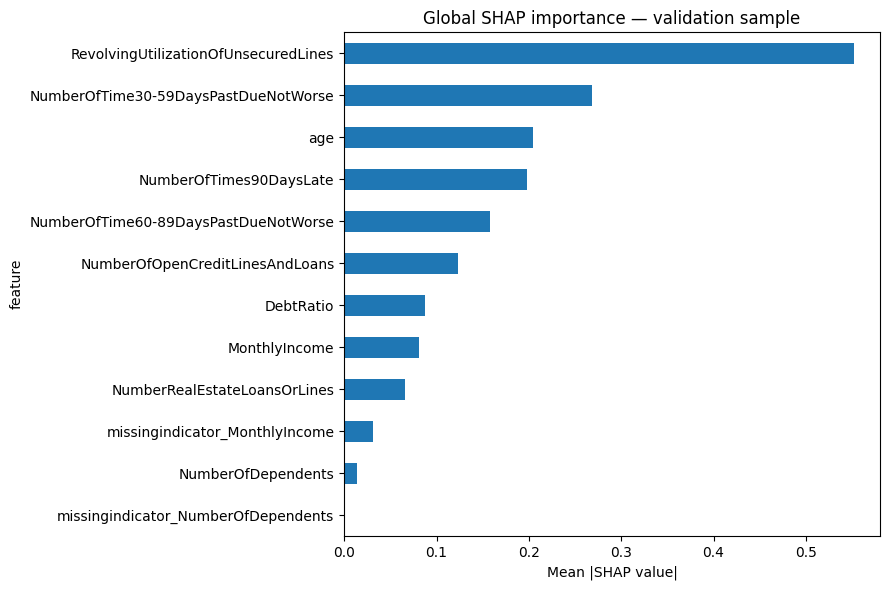

In [13]:
importance = pd.read_csv(TABLES / 'shap_global_importance.csv').head(15)
display(importance.round(5))
importance.sort_values('mean_absolute_shap').plot.barh(
    x='feature', y='mean_absolute_shap', legend=False, figsize=(9, 6),
    title='Global SHAP importance — validation sample')
plt.xlabel('Mean |SHAP value|'); plt.tight_layout(); plt.savefig(FIGURES / 'shap_global_importance.png', dpi=160, bbox_inches='tight'); plt.show()

## Representative local explanations
Cases are chosen deterministically from validation: a high-risk positive, a false positive and a false negative when available. Feature contributions explain the model score, not the reason a borrower became delinquent.

,case_type,sample_id,y_true,y_pred_proba,model_name,split,predicted_label
0,highest_risk_positive,21879,1,0.851815,xgboost_standard_tuned,validation,1
1,false_positive,106886,0,0.818104,xgboost_standard_tuned,validation,1
2,false_negative,108343,1,0.498307,xgboost_standard_tuned,validation,0


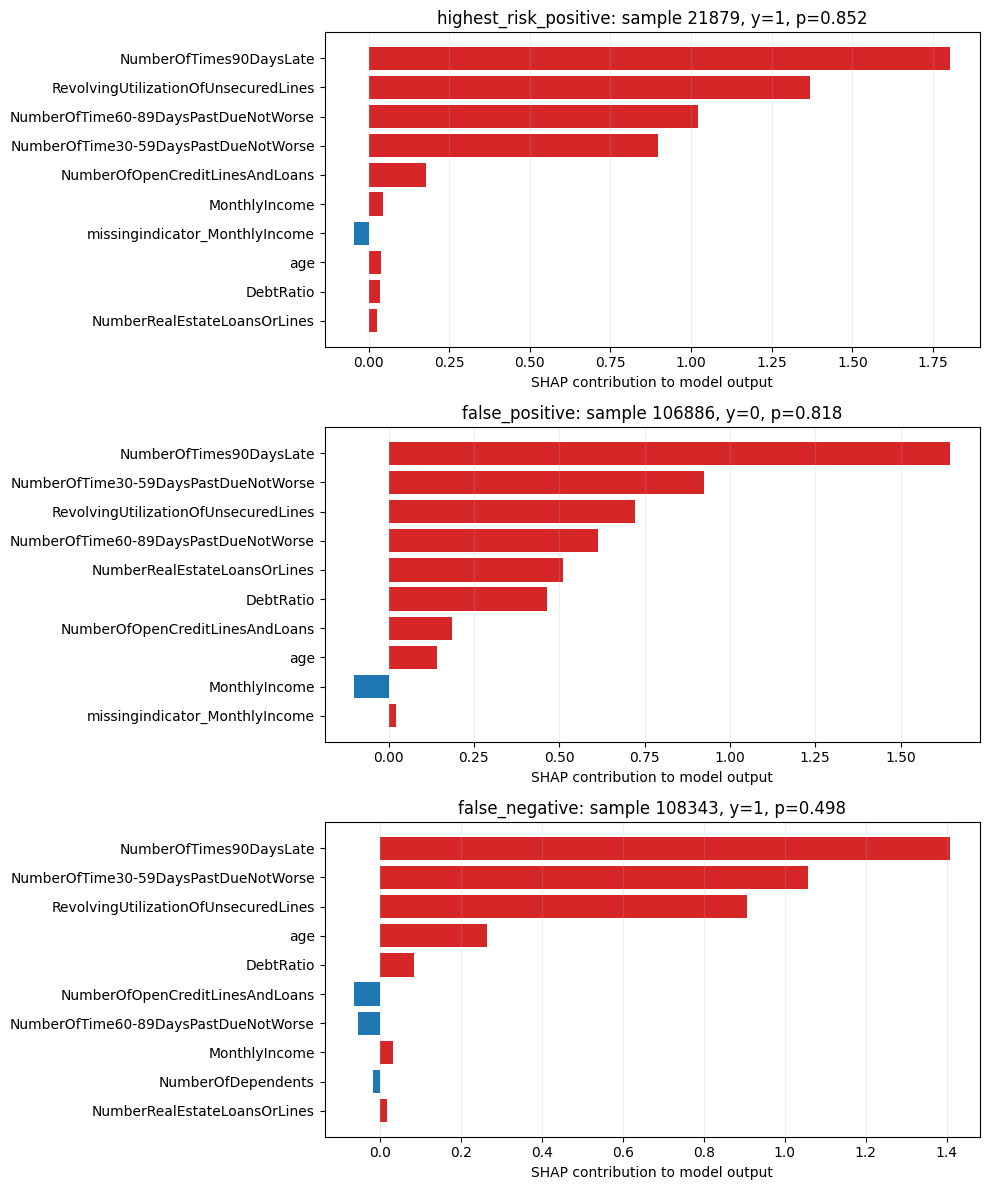

In [14]:
cases = pd.read_csv(TABLES / 'shap_representative_cases.csv')
local = pd.read_csv(TABLES / 'shap_local_explanations.csv')
display(cases)
fig, axes = plt.subplots(len(cases), 1, figsize=(10, 4 * len(cases)), squeeze=False)
for ax, case in zip(axes.flat, cases.itertuples()):
    values = local[local['sample_id'].eq(case.sample_id)].sort_values('absolute_shap')
    colors = np.where(values['shap_value'] >= 0, 'tab:red', 'tab:blue')
    ax.barh(values['feature'], values['shap_value'], color=colors)
    ax.set_title(f'{case.case_type}: sample {case.sample_id}, y={case.y_true}, p={case.y_pred_proba:.3f}')
    ax.set_xlabel('SHAP contribution to model output'); ax.grid(axis='x', alpha=.2)
plt.tight_layout(); plt.savefig(FIGURES / 'shap_local_cases.png', dpi=160, bbox_inches='tight'); plt.show()

## Handoff and limitations
- Member 5 must choose cost-sensitive thresholds from validation predictions only and state the `C_FN:C_FP` orientation.
- Member 1 performs one final locked test evaluation only after model, calibration and threshold decisions are approved.
- Bootstrap intervals quantify sampling uncertainty conditional on this fixed validation split; they do not replace external or temporal validation.
- Duplicate sensitivity is descriptive and does not authorize changing the approved shared split.
- Calibration and SHAP outputs are development evidence, not production or causal claims.